# 典型的信号处理运算

## 从信号到频谱：一步一步理解单边幅度谱

先别担心公式。我们要回答的问题很简单：**这段声音里有哪些音调？每个音调有多强？**

### 1. 信号是什么？

生成的 `signal` 是一串数字。每个数字表示麦克风在一个采样时刻测到的声音大小。把它画在时间轴上，就是波形图。

波形能告诉我们声音怎样随时间变化，但如果几种音调混在一起，光看波形不容易分辨它们。频谱提供另一种视角：横轴是频率，纵轴表示相应频率成分的大小。

### 2. 频率可以先理解成“每秒重复多少次”

440 Hz 表示每秒振动 440 次。生成的信号主要是一个 440 Hz 正弦波，振幅为 0.5；此外还加了随机噪声。所以频谱应该在 440 Hz 附近有一个明显的峰，其他频率也会因为噪声而有较小的值。

### 3. FFT 为什么会有正频率和负频率？

FFT 用一组复数振荡波来表示信号。数学上，振荡可以从两个方向来描述，于是频谱会包含正频率和负频率。这里的“负频率”是数学表示的一部分，不是另一种麦克风声音。

对实数信号（ `signal` 每个采样值都是实数），正频率和负频率的 FFT 系数互为复共轭，因此它们的**幅度相同**。可以把完整频谱想成左右两边重复展示同一批幅度信息。我们通常只画非负频率，这叫**单边频谱**。

### 4. `rfft` 做了什么？

```python
X = rfft(signal)
freqs = rfftfreq(N, d=1 / fs)
```

- `rfft(signal)`：因为输入是实数信号，只计算非负频率这一半的 FFT 系数。
- `rfftfreq(...)`：给这些系数配上频率坐标，单位是 Hz。
- `np.abs(X)`：取每个复数系数的大小，暂时还不是最终的正弦波振幅。

`rfft` 只是省去重复计算；它**不会自动把单边幅度乘 2**。

### 5. 为什么先除以 N？

FFT 把 N 个采样点累加到每个频率系数里，所以系数大小会随采样点数 N 增大。除以 N 可以消除这个影响：

```python
magnitude = np.abs(X) / N
```

对于振幅为 A 的正弦波，完整频谱的正、负频率各占约 A/2。除以 N 后，单边谱中对应的正频率仍约为 A/2。为了让图上的峰值回到原来的正弦波振幅 A，需要把这部分乘以 2。

### 6. 为什么 DC 和 Nyquist 不乘 2？

普通正频率都有一个对应的负频率伙伴，所以把两边合并时要乘 2。但有两个特殊位置没有需要合并的伙伴：

- **DC（0 Hz）**：表示信号的平均值，不是一对正负频率。
- **Nyquist（采样率的一半）**：当 N 为偶数时，它是频率轴的最后一个点，也不需要再乘 2。

所以代码写成：

```python
magnitude = np.abs(X) / N
if N % 2 == 0:
    magnitude[1:-1] *= 2  # 跳过 DC 和 Nyquist
else:
    magnitude[1:] *= 2    # 跳过 DC
```

### 7. 这张图应该怎么看？

横轴告诉你频率，纵轴给出单边幅度估计。你的正弦波振幅是 0.5，因此 440 Hz 附近的峰值应接近 0.5。加上噪声后，峰值会有些波动；噪声也会让其他频率处出现较小的起伏。

**记住一句话：**对实数信号，负频率的幅度和正频率重复；单边幅度谱只展示非负频率，并把普通正频率的幅度乘 2，让它更接近原信号中正弦波的振幅。

这段代码算的是“幅度谱”。以后遇到功率谱或功率谱密度时，归一化方法会不同，先不用把它们混在一起。

音频已保存为: simulated_mic_440Hz.wav


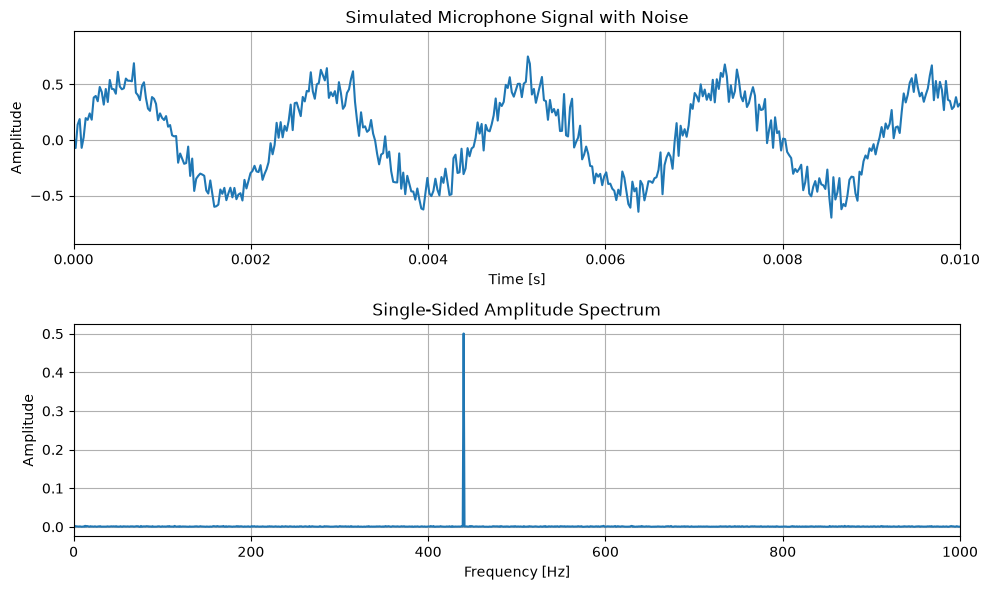

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import write
from scipy.fft import rfft, rfftfreq

# 模拟一个麦克风信号：一个 440 Hz 的正弦波叠加高斯白噪声，并保存为 WAV 文件。
# 采样参数
fs = 44100 # 采样率，即每秒采样点数
duration = 1.0 # 持续时间，单位为秒
N = int(fs * duration)
t = np.arange(N) / fs  # 采样间隔严格为 1/fs

# 生成 440 Hz 正弦波并加入高斯白噪声
frequency = 440
rng = np.random.default_rng(42)  # 固定随机种子，方便复现
signal = 0.5 * np.sin(2 * np.pi * frequency * t)
signal += 0.1 * rng.normal(size=N)

# 保存为 WAV 文件
audio_data = np.clip(signal, -1.0, 1.0)
audio_data = (audio_data * 32767).astype(np.int16)

filename = "simulated_mic_440Hz.wav"
write(filename, fs, audio_data)
print(f"音频已保存为: {filename}")

# 计算单边幅度谱
# 为什么是单边幅度谱？因为我们只关心正频率部分，负频率部分是对称的。
X = rfft(signal)
freqs = rfftfreq(N, d=1 / fs)
magnitude = np.abs(X) / N

# 单边频谱需要补回负频率一侧的幅度。
# DC 点不乘 2；偶数长度时，Nyquist 点也不乘 2。
if N % 2 == 0:
    magnitude[1:-1] *= 2
else:
    magnitude[1:] *= 2

# 绘图
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t, signal)
plt.title("Simulated Microphone Signal with Noise")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.xlim(0, 0.01)

plt.subplot(2, 1, 2)
plt.plot(freqs, magnitude)
plt.title("Single-Sided Amplitude Spectrum")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.xlim(0, 1000)

plt.tight_layout()
plt.show()

多音调音频已保存为: simulated_mic_multiple_tones.wav


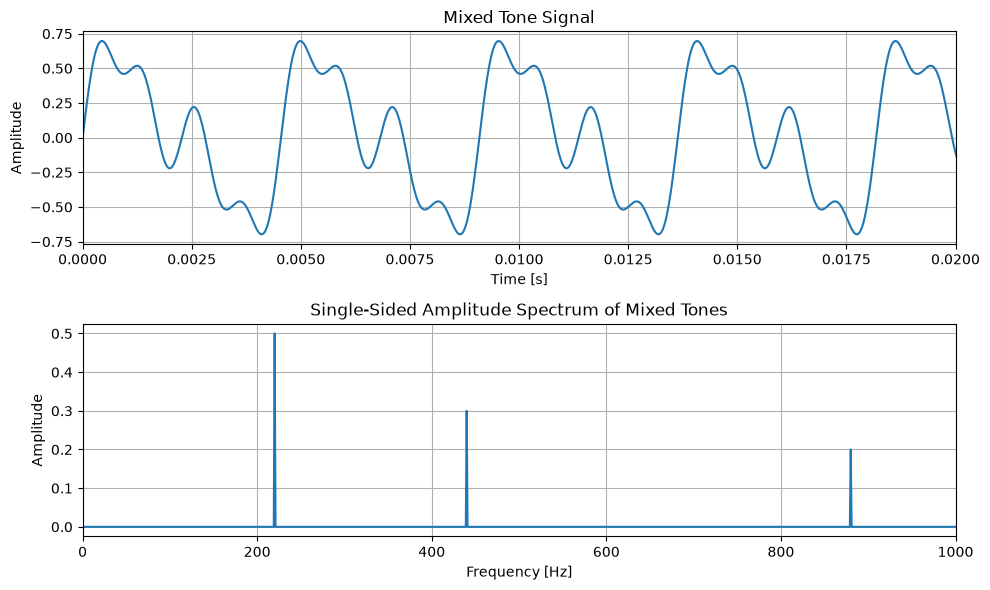

In [5]:
# 生成多个音调混合的音频
# 每个正弦波代表一个音调；把它们相加，就得到混合信号。
frequencies = [220, 440, 880]  # 三个音调，单位 Hz
amplitudes = [0.5, 0.3, 0.2]   # 各音调的振幅

mixed_signal = np.zeros(N)
for f, amp in zip(frequencies, amplitudes):
    mixed_signal += amp * np.sin(2 * np.pi * f * t)

# 保存成 WAV。混合信号峰值不会超过振幅之和；这里仍做裁剪以保护 int16 范围。
mixed_audio = np.clip(mixed_signal, -1.0, 1.0)
mixed_audio = (mixed_audio * 32767).astype(np.int16)
mixed_filename = "simulated_mic_multiple_tones.wav"
write(mixed_filename, fs, mixed_audio)
print(f"多音调音频已保存为: {mixed_filename}")

# 用单边幅度谱观察混合信号中的音调
X_mixed = rfft(mixed_signal)
mixed_magnitude = np.abs(X_mixed) / N
if N % 2 == 0:
    mixed_magnitude[1:-1] *= 2  # DC 和 Nyquist 不乘 2
else:
    mixed_magnitude[1:] *= 2    # DC 不乘 2

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(t, mixed_signal)
plt.title("Mixed Tone Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.xlim(0, 0.02)  # 只看前 20 毫秒

plt.subplot(2, 1, 2)
plt.plot(freqs, mixed_magnitude)
plt.title("Single-Sided Amplitude Spectrum of Mixed Tones")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.xlim(0, 1000)
plt.tight_layout()
plt.show()

# 频谱中应在 220、440、880 Hz 附近看到三个峰，峰高分别接近 0.5、0.3、0.2。

## 简单时域运算：缩放、延迟、相加

先只看波形，不急着做频谱。把离散信号 `x[n]` 想成一排按时间顺序记录的数值。

### A. 缩放：把每个数乘上同一个倍数

```text
y[n] = a · x[n]
```

如果 `a = 2`，波形的高度变成两倍；如果 `a = 0.5`，高度变成一半。这里改变的是振幅，时间位置和波形形状不变。若 `a` 是负数，波形还会上下翻转。

### B. 延迟：把整段波形往后挪

```text
y[n] = x[n - n0]
```

`n0` 是延迟的采样点数。采样率为 `fs` 时，延迟时间是 `n0 / fs` 秒。波形形状不变，只是晚一些出现。实际数组长度有限，挪动后空出来的位置用 0 填充，末尾超出范围的样本会被舍弃。

### C. 相加：把两个信号逐点叠在一起

```text
y[n] = x1[n] + x2[n]
```

每个时刻把两个信号的数值相加。声音混合就是一个常见例子：不同音调对应的波形叠加成一个波形。相加后振幅可能变大，所以实际音频保存前要留意是否超出允许范围。

下面的代码用 5 Hz 和 12 Hz 两个简单正弦波演示这些操作。频率选得较低，只是为了方便看清波形；它们不是语音音调。

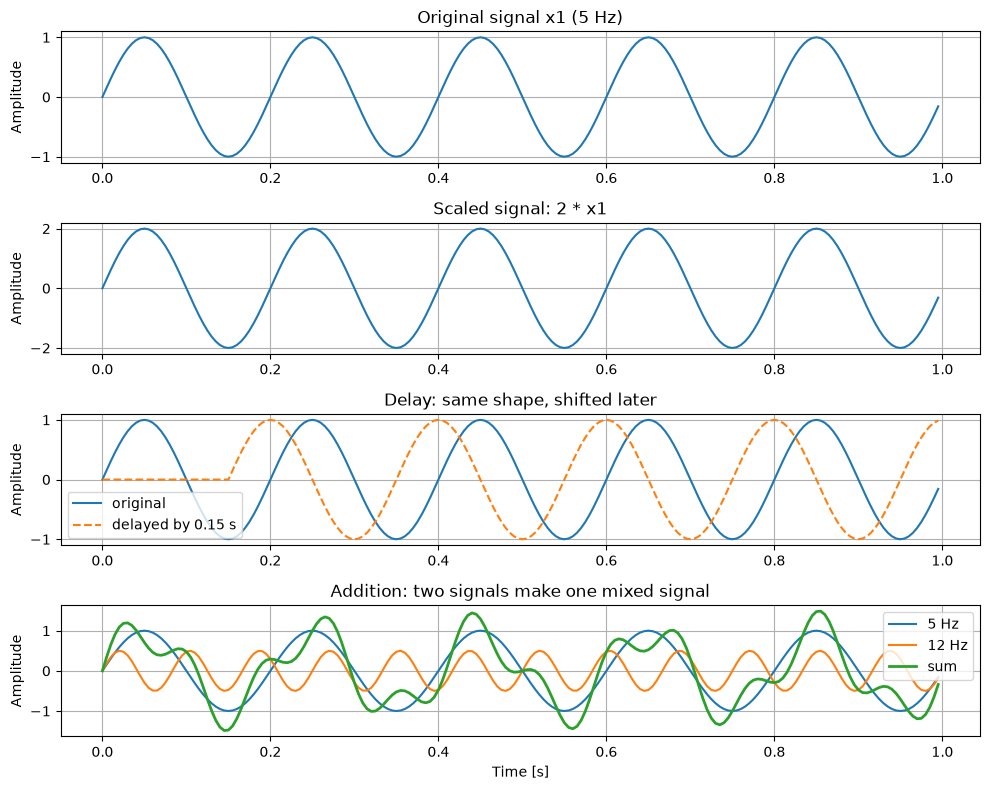

In [6]:
# 这个例子独立设置参数，方便单独运行这一课
fs_demo = 200       # 每秒采样 200 次
duration_demo = 1.0
N_demo = int(fs_demo * duration_demo)
t_demo = np.arange(N_demo) / fs_demo

# 两个频率不同的简单信号
x1 = np.sin(2 * np.pi * 5 * t_demo)   # 5 Hz
x2 = 0.5 * np.sin(2 * np.pi * 12 * t_demo)  # 12 Hz，振幅较小

# A. 缩放：振幅乘 2
x_scaled = 2 * x1

# B. 延迟：延迟 30 个采样点，也就是 30 / 200 = 0.15 秒
delay_samples = 30
x_delayed = np.zeros_like(x1)
x_delayed[delay_samples:] = x1[:-delay_samples]

# C. 相加：两个信号逐点相加，形成混合信号
x_mixed = x1 + x2

plt.figure(figsize=(10, 8))
plt.subplot(4, 1, 1)
plt.plot(t_demo, x1)
plt.title("Original signal x1 (5 Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t_demo, x_scaled)
plt.title("Scaled signal: 2 * x1")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t_demo, x1, label="original")
plt.plot(t_demo, x_delayed, label="delayed by 0.15 s", linestyle="--")
plt.title("Delay: same shape, shifted later")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(t_demo, x1, label="5 Hz")
plt.plot(t_demo, x2, label="12 Hz")
plt.plot(t_demo, x_mixed, label="sum", linewidth=2)
plt.title("Addition: two signals make one mixed signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 滤波

```留下想要的变化，削弱不想要的变化```

滤波可以先理解成“按变化快慢筛选信号”。例如，麦克风信号里有缓慢变化的语音和尖锐的高频噪声时，可以尝试削弱高频部分。

下面用一个 80 Hz 正弦波当作有用信号，再加上 450 Hz 的快速振荡当作干扰。移动平均滤波器会把相邻样本取平均，快速变化通常会被平滑掉。它很适合做入门演示，但并不是理想滤波器：有用信号也可能被削弱，效果取决于窗口长度。

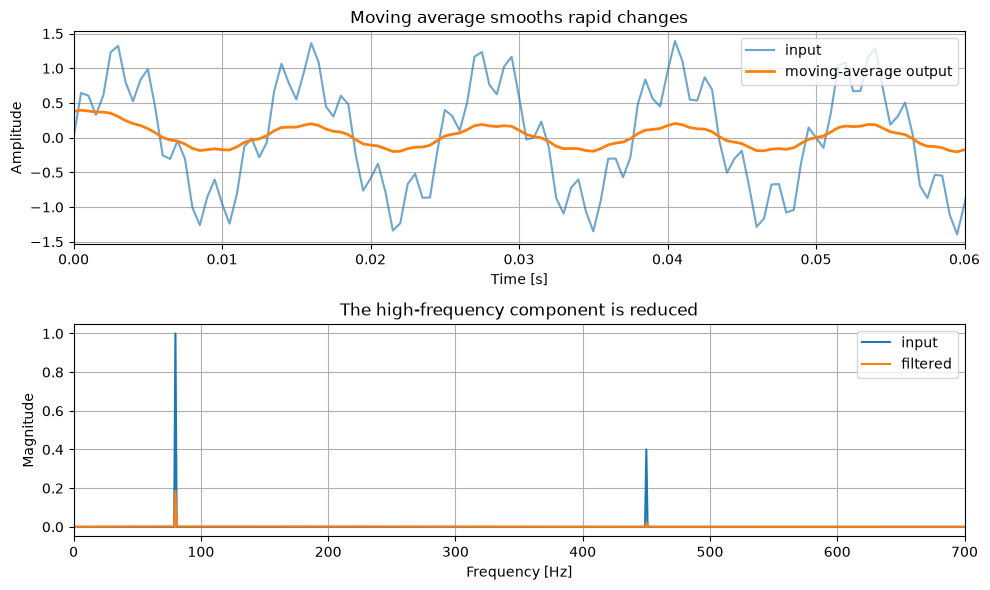

In [7]:
# 用移动平均做一个简单的低通滤波演示
fs_f = 2000
duration_f = 1.0
N_f = int(fs_f * duration_f)
t_f = np.arange(N_f) / fs_f
useful_f = np.sin(2 * np.pi * 80 * t_f)
interference_f = 0.4 * np.sin(2 * np.pi * 450 * t_f)
noisy_f = useful_f + interference_f

window_f = 21
filtered_f = np.convolve(noisy_f, np.ones(window_f) / window_f, mode="same")

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(t_f, noisy_f, label="input", alpha=0.65)
plt.plot(t_f, filtered_f, label="moving-average output", linewidth=2)
plt.xlim(0, 0.06)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Moving average smooths rapid changes")
plt.grid(True)
plt.legend()

plt.subplot(2, 1, 2)
f_f = rfftfreq(N_f, d=1 / fs_f)
mag_in_f = np.abs(rfft(noisy_f)) / N_f
mag_out_f = np.abs(rfft(filtered_f)) / N_f
mag_in_f[1:-1] *= 2
mag_out_f[1:-1] *= 2
plt.plot(f_f, mag_in_f, label="input")
plt.plot(f_f, mag_out_f, label="filtered")
plt.xlim(0, 700)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.title("The high-frequency component is reduced")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 产生复值信号

### 实数信号和复数信号

实数信号是我们在现实世界中用传感器（麦克风、电压表）直接测到的物理量。复数信号（通常指解析信号）是为了数学计算方便和提取物理特征，人为构造出来的信号（二维数字系统），目的是便于表示幅度、相位和频率。

例如，普通麦克风采样通常是一串实数：每个采样点是一个实际测得的数值。复数信号则在每个时刻同时记录两个数：实部 I 和虚部 Q，写成 `z = I + 1j * Q`。这里，I即是In-phase（同相），Q即Quadrature（正交）。

麦克风：`x(t) = cos(2π f t)`，f是频率，t是时间，这个是单纯的一维实数。（一维空间（数轴，点只能在一条线上移动），X是时间，Y是振幅）

通过Hilbert Transform（希尔伯特变换，相移90度，cos变成sin），变成复数信号：`z(t) = cos(2π f t) + 1j sin(2π f t)`，这个是二维空间（平面，点可以在一个面上任意移动），X轴是实部I，Y轴是虚部Q，反映了信号在真实物理空间中的全貌（幅度和相位），幅度表示离原点多远（`sqrt(I^2+Q^2)`），相位表示转到哪个角度（`arctan(Q/I)`）。

![实数和复数](./images/实数复数.png)

### 傅里叶变量：连续时间和离散时间

连续信号写作 `x(t)`，`t` 可以取任意时间；采样后写作 `x[n]`，这里只在整数编号 `n` 上有值，且 `x[n] = x(n / fs)`。这是“连续时间信号”和“离散时间信号”的区别。

做傅里叶分析时，横轴表示频率。连续时间常用 `f`（Hz，周/秒），也常用角频率 `ω = 2πf`（弧度/秒）。离散时间常用 `Ω`（弧度/采样），它和实际频率的关系是 `Ω = 2πf/fs`。先把它理解成“每个采样点相位前进多少”；暂时不必记推导。

下面把一条连续正弦波在计算机里采样，并画出复指数的实部和虚部。电脑无法画出真正连续的曲线，所以图中的连续线只是视觉上的参考，圆点才是采样值。

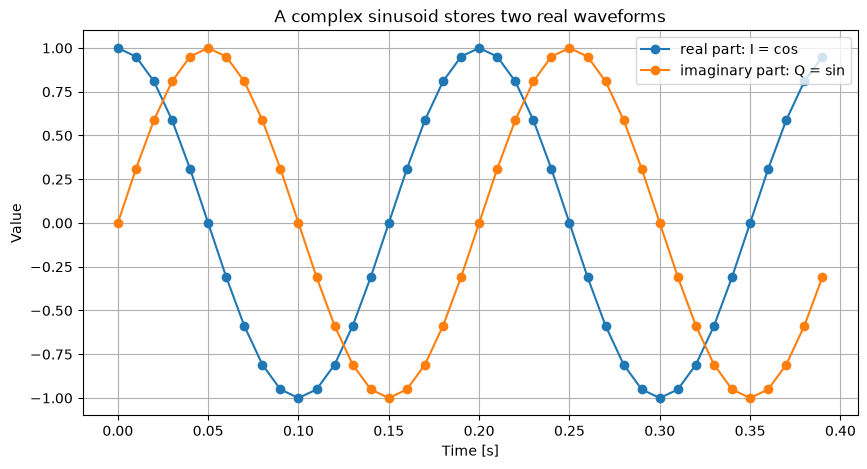

First complex samples: [1.        +0.j         0.95105652+0.30901699j 0.80901699+0.58778525j
 0.58778525+0.80901699j 0.30901699+0.95105652j]
Magnitude of each sample: [1. 1. 1. 1. 1.]
Digital angular frequency Ω [rad/sample]: 0.3141592653589793


In [11]:
# 用复指数同时表示一对正交的正弦波
fs_c = 100
f_c = 5
duration_c = 0.4
t_c = np.arange(int(fs_c * duration_c)) / fs_c
z_c = np.exp(1j * 2 * np.pi * f_c * t_c)

plt.figure(figsize=(10, 5))
plt.plot(t_c, z_c.real, "o-", label="real part: I = cos")
plt.plot(t_c, z_c.imag, "o-", label="imaginary part: Q = sin")
plt.xlabel("Time [s]")
plt.ylabel("Value")
plt.title("A complex sinusoid stores two real waveforms")
plt.grid(True)
plt.legend()
plt.show()

print("First complex samples:", z_c[:5])
print("Magnitude of each sample:", np.abs(z_c[:5]))
print("Digital angular frequency Ω [rad/sample]:", 2 * np.pi * f_c / fs_c)

## 振幅调制：用一个快振荡承载慢变化的信息

调制可以理解为“把信息信号放到一个更快的载波上”。这里慢变化的消息信号是 `m(t)`，载波是高频余弦波。振幅调制（AM）让载波的振幅跟着消息变化：

```text
s(t) = [1 + μ m(t)] cos(2π f_c t)
```

`μ` 控制调制深度。我们先用单音消息做演示。图里高频振荡的外轮廓（包络）会跟随低频消息上下变化。频谱上，除了载波频率 `f_c`，还会在 `f_c - f_m` 和 `f_c + f_m` 附近出现边带。

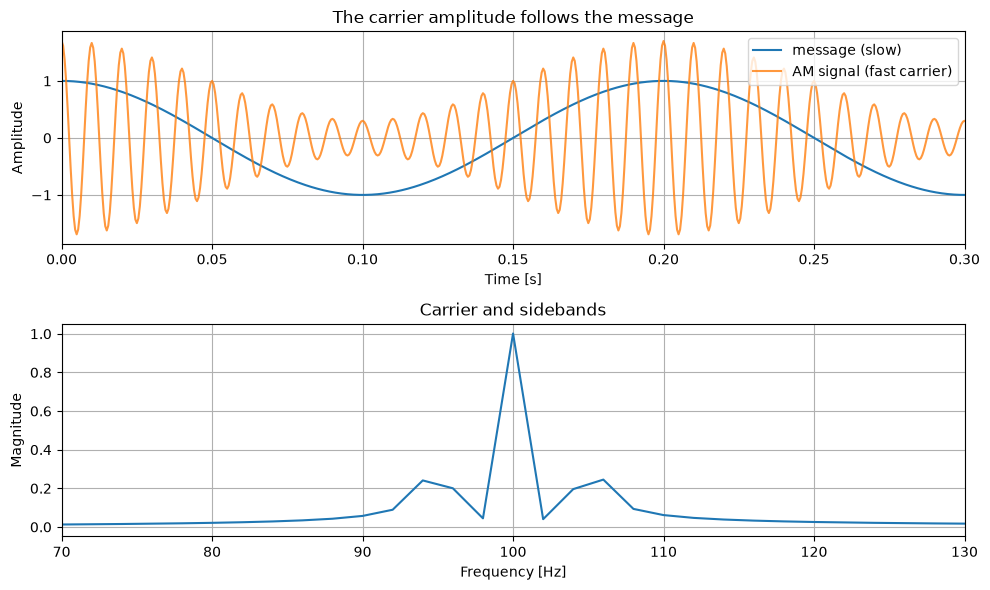

Look near fc-fm, fc, fc+fm: 95 100 105 Hz


In [9]:
fs_am = 2000
duration_am = 0.5
N_am = int(fs_am * duration_am)
t_am = np.arange(N_am) / fs_am
fm_am = 5
fc_am = 100
mu_am = 0.7
message_am = np.cos(2 * np.pi * fm_am * t_am)
carrier_am = np.cos(2 * np.pi * fc_am * t_am)
am_signal = (1 + mu_am * message_am) * carrier_am

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(t_am, message_am, label="message (slow)")
plt.plot(t_am, am_signal, label="AM signal (fast carrier)", alpha=0.8)
plt.xlim(0, 0.3)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("The carrier amplitude follows the message")
plt.grid(True)
plt.legend()

f_am = rfftfreq(N_am, d=1 / fs_am)
mag_am = np.abs(rfft(am_signal)) / N_am
mag_am[1:-1] *= 2
plt.subplot(2, 1, 2)
plt.plot(f_am, mag_am)
plt.xlim(70, 130)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.title("Carrier and sidebands")
plt.grid(True)
plt.tight_layout()
plt.show()
print("Look near fc-fm, fc, fc+fm:", fc_am-fm_am, fc_am, fc_am+fm_am, "Hz")

## 复用和解复用：让多个消息共用一条信道

**复用**是把多个消息合在一起传输；**解复用**是接收后把它们分开。一个直观方法叫频分复用（FDM）：给不同消息安排不同的载波频率，再把调制后的信号相加。接收端针对每个载波解调并低通滤波，就能取回对应消息。

下面的例子把两条低频消息分别放到 300 Hz 和 600 Hz 载波上。它假定收发双方知道载波频率且时间同步。真实通信还需要处理噪声、同步误差、频带规划等问题。

In [ ]:
from scipy.signal import butter, sosfiltfilt

fs_mux = 4000
duration_mux = 1.0
N_mux = int(fs_mux * duration_mux)
t_mux = np.arange(N_mux) / fs_mux
msg1_mux = np.sin(2 * np.pi * 5 * t_mux)
msg2_mux = 0.7 * np.sin(2 * np.pi * 8 * t_mux)
fc1_mux, fc2_mux = 300, 600

channel_mux = (msg1_mux * np.cos(2 * np.pi * fc1_mux * t_mux)
               + msg2_mux * np.cos(2 * np.pi * fc2_mux * t_mux))
# 同步解调：乘回对应载波，再用低通滤波器去掉高频项
sos_mux = butter(4, 30, btype="lowpass", fs=fs_mux, output="sos")
rec1_mux = 2 * sosfiltfilt(sos_mux, channel_mux * np.cos(2 * np.pi * fc1_mux * t_mux))
rec2_mux = 2 * sosfiltfilt(sos_mux, channel_mux * np.cos(2 * np.pi * fc2_mux * t_mux))

plt.figure(figsize=(10, 6))
plt.subplot(3, 1, 1)
plt.plot(t_mux, channel_mux)
plt.xlim(0, 0.15)
plt.ylabel("Amplitude")
plt.title("Combined channel signal")
plt.grid(True)
plt.subplot(3, 1, 2)
plt.plot(t_mux, msg1_mux, label="original message 1")
plt.plot(t_mux, rec1_mux, "--", label="recovered message 1")
plt.xlim(0, 0.6)
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.subplot(3, 1, 3)
plt.plot(t_mux, msg2_mux, label="original message 2")
plt.plot(t_mux, rec2_mux, "--", label="recovered message 2")
plt.xlim(0, 0.6)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 正交振幅调制（QAM）：用 I 和 Q 同时承载信息

QAM 是“正交振幅调制”的简称。它用同一个载波频率上的两条互相正交的波来传信息：余弦载波承载 I，正弦载波承载 Q。因为两条载波相差四分之一周期，接收端可以分别相关/解调它们。

```text
s(t) = I(t) cos(2π f_c t) - Q(t) sin(2π f_c t)
```

每个符号由一对数值 `(I, Q)` 表示。把这些点画在 I-Q 平面上就是星座图。下面用 16-QAM 的四个 I 电平和四个 Q 电平演示，共有 16 种可能的符号。我们用整符号周期做简单同步解调，让入门例子易于观察。

In [ ]:
rng_qam = np.random.default_rng(7)
fs_qam = 10000
fc_qam = 1000
symbols_qam = 20
samples_per_symbol_qam = 100
levels_qam = np.array([-3, -1, 1, 3])
I_qam = rng_qam.choice(levels_qam, size=symbols_qam)
Q_qam = rng_qam.choice(levels_qam, size=symbols_qam)
I_up_qam = np.repeat(I_qam, samples_per_symbol_qam)
Q_up_qam = np.repeat(Q_qam, samples_per_symbol_qam)
t_qam = np.arange(len(I_up_qam)) / fs_qam

qam_signal = (I_up_qam * np.cos(2 * np.pi * fc_qam * t_qam)
              - Q_up_qam * np.sin(2 * np.pi * fc_qam * t_qam))
# 同步解调，并在每个符号区间取平均
I_hat_qam = (2 * qam_signal * np.cos(2 * np.pi * fc_qam * t_qam)).reshape(-1, samples_per_symbol_qam).mean(axis=1)
Q_hat_qam = (-2 * qam_signal * np.sin(2 * np.pi * fc_qam * t_qam)).reshape(-1, samples_per_symbol_qam).mean(axis=1)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(t_qam, qam_signal)
plt.xlim(0, 0.04)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("QAM waveform (first 4 symbols)")
plt.grid(True)
plt.subplot(1, 2, 2)
plt.scatter(I_qam, Q_qam, label="transmitted")
plt.scatter(I_hat_qam, Q_hat_qam, marker="x", label="demodulated")
plt.xticks(levels_qam)
plt.yticks(levels_qam)
plt.xlabel("I")
plt.ylabel("Q")
plt.title("16-QAM constellation")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

## 振荡器：按固定步长持续推进相位

振荡器会持续产生重复振荡的信号。最熟悉的例子是正弦波发生器。数字系统里可以直接计算 `sin(2π f n/fs)`；也可以每个采样点把相位增加固定量 `Ω = 2πf/fs`。

用复数写时，每次乘上 `exp(1j*Ω)` 就像在复平面上转一个固定角度。取实部得到余弦，取虚部得到正弦。这就是数字控制振荡器（NCO）的一个简单模型，也是 I/Q 信号生成的基础。

In [ ]:
fs_osc = 1000
f_osc = 50
N_osc = 100
t_osc = np.arange(N_osc) / fs_osc
omega_osc = 2 * np.pi * f_osc / fs_osc
rotation_osc = np.exp(1j * omega_osc)
z_osc = np.empty(N_osc, dtype=complex)
z_osc[0] = 1 + 0j
for n_osc in range(1, N_osc):
    z_osc[n_osc] = z_osc[n_osc - 1] * rotation_osc

cos_direct_osc = np.cos(2 * np.pi * f_osc * t_osc)
plt.figure(figsize=(10, 4))
plt.plot(t_osc, cos_direct_osc, label="direct cosine")
plt.plot(t_osc, z_osc.real, "--", label="oscillator real part")
plt.plot(t_osc, z_osc.imag, ":", label="oscillator imaginary part")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("A digital oscillator advances phase sample by sample")
plt.grid(True)
plt.legend()
plt.show()
print("Phase step Ω [rad/sample]:", omega_osc)
print("Maximum magnitude deviation from 1:", np.max(np.abs(np.abs(z_osc) - 1)))